# Recovery curves of the bleached droplets

spot = bleached region (spot labels), tot = whole bleached droplet (droplet labels), ref = reference droplets (static, unbleached); all are **mean** intensities per frame.

   - A(t) = spot(t) / ref(t)
   - B(t) = A(t) / A(pre)
   - C(t) = tot(t) / ref(t)
   - D(t) = C(t) / C (pre)
   - final = B(t) / D(t)

Since the reference cancels, final is equivalent to final(t) = [spot(t) / tot(t)] / [spot(pre) / tot(pre)]. So final compares the spot’s brightness relative to its own droplet with what it was before the bleach.

final = 1: the spot’s brightness relative to its droplet is as before the bleach.

No background subtraction: the microscope clips the background at 0.



In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from matplotlib.ticker import MaxNLocator, MultipleLocator

# 0. Settings and data

In [2]:
SEG_DIR = Path("results/segmentation")               # folder of notebook 01
BLEACH_DIR = Path("results/bleach_detect")           # folder of notebook 02
SAT_DIR = Path("results/saturation_report")          # folder of notebook 03 (only used to mark droplets)
OUT_DIR = Path("results/recovery_curves")
figures = {}
 
FRAME_PRE = 0


In [3]:
# Load stacks, labels and droplet tables

files = sorted(Path("data").glob("*.tif"))
stacks, droplet_labels, spot_labels, droplets_info = {}, {}, {}, {}

for f in files:
    name = f.stem
    stacks[name] = tifffile.imread(f).astype(np.float64)
    droplet_labels[name] = tifffile.imread(SEG_DIR / f"{name}_droplet_labels.tif")
    spot_labels[name] = tifffile.imread(BLEACH_DIR / f"{name}_spot_labels.tif")
 
    tab = pd.read_csv(BLEACH_DIR / f"{name}_all_droplets.csv")
    tab = tab[~tab["moved"]].copy()                          # moved at the bleach: excluded in notebook 02
    tab["role"] = np.where(tab["bleached"], "bleached", "reference")
 
    sat_file = SAT_DIR / f"{name}_saturation.csv"             # saturation report, if available
    if sat_file.exists():
        sat = pd.read_csv(sat_file)[["droplet", "spot_pre_above", "droplet_pre_above"]]
        tab = tab.merge(sat, on="droplet", how="left")
    else:
        tab["spot_pre_above"] = False
        tab["droplet_pre_above"] = False
    droplets_info[name] = tab[["droplet", "role", "spot_pre_above", "droplet_pre_above"]]
 
    n_b = (tab["role"] == "bleached").sum()
    print(f"{name}: {stacks[name].shape[0]} frames, {n_b} bleached + {len(tab) - n_b} reference droplets")

Apt2+Ca_2: 21 frames, 16 bleached + 99 reference droplets
Apt2_1: 21 frames, 9 bleached + 39 reference droplets
PEG_3: 21 frames, 10 bleached + 32 reference droplets


# 1. Intensities and normalization

For every bleached droplet and every frame: mean intensity of its spot and of the whole droplet (tot), and of the reference droplets (ref: mean of all their pixels pooled together, one curve per file).

Then the normalization steps A, B, C, D and final. Everything goes into one table: one row per file, droplet and frame.

In [4]:
# Measure and normalize

rows = []

for name, tab in droplets_info.items():
    stack, labels, spots = stacks[name], droplet_labels[name], spot_labels[name]
    n_frames = stack.shape[0]
 
    ref_ids = tab.loc[tab["role"] == "reference", "droplet"]
    ref = stack[:, np.isin(labels, ref_ids)].mean(axis=1)          # the mean intensity of all reference pixels, one value per frame
 
    for _, d_row in tab[tab["role"] == "bleached"].iterrows():
        d = d_row["droplet"]
        spot = stack[:, spots == d].mean(axis=1)        # mean intensity of the bleached region in each frame
        tot = stack[:, labels == d].mean(axis=1)        # mean intensity of the whole bleached droplet in each frame
 
        A = spot / ref
        B = A / A[FRAME_PRE]
        C = tot / ref
        D = C / C[FRAME_PRE]
        final = B / D
 
        rows.append(pd.DataFrame({
            "file": name, "droplet": d, "frame": np.arange(n_frames),
            "spot": spot, "tot": tot, "ref": ref,
            "A": A, "B": B, "C": C, "D": D, "final": final,
            "spot_pre_above_sat_th": d_row["spot_pre_above"], "droplet_pre_above_sat_th": d_row["droplet_pre_above"]}))
 
curves = pd.concat(rows, ignore_index=True)

# 2. Plots

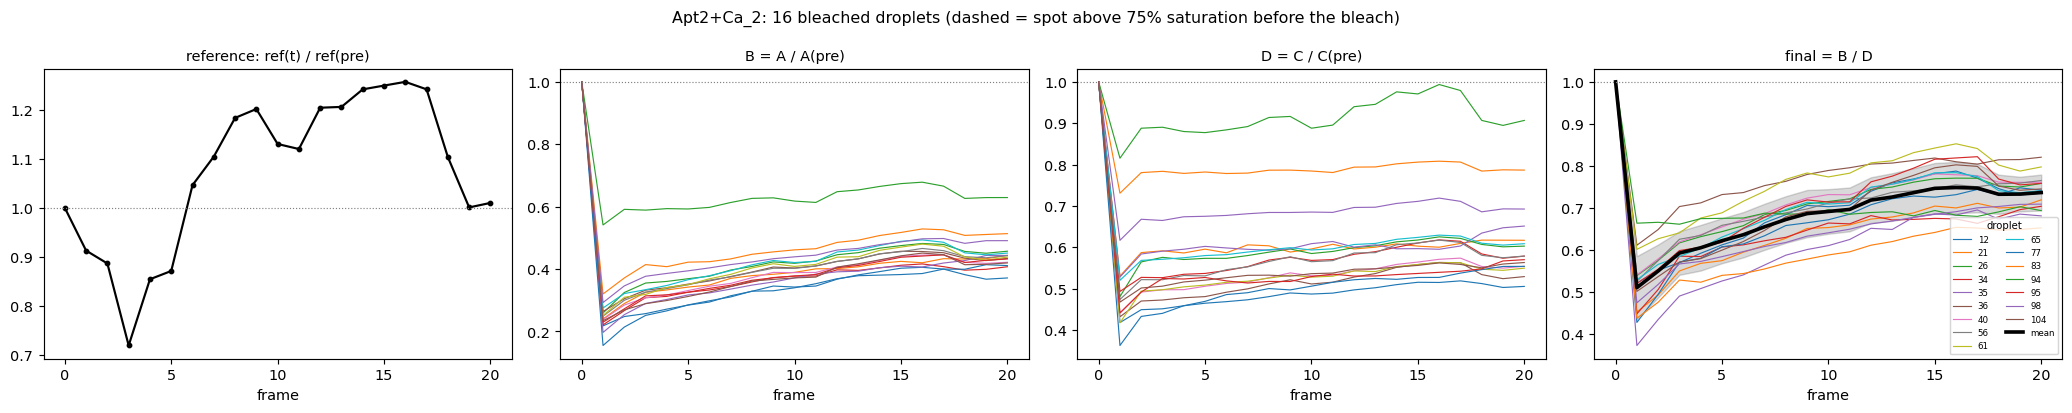

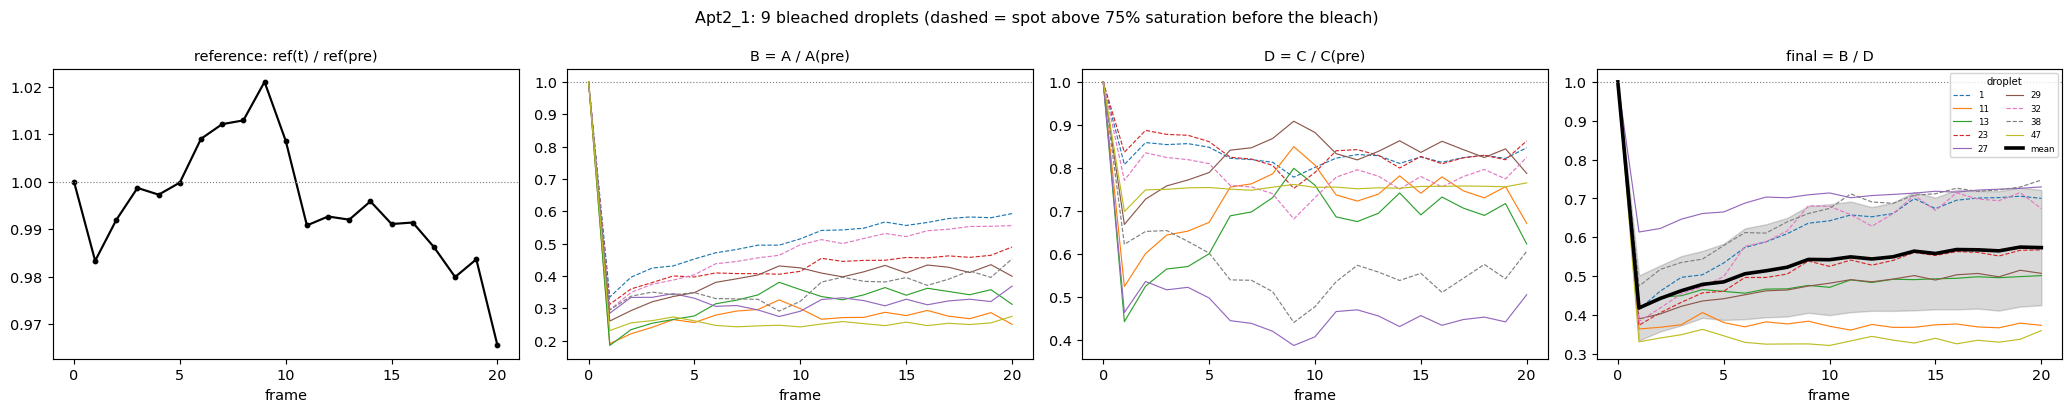

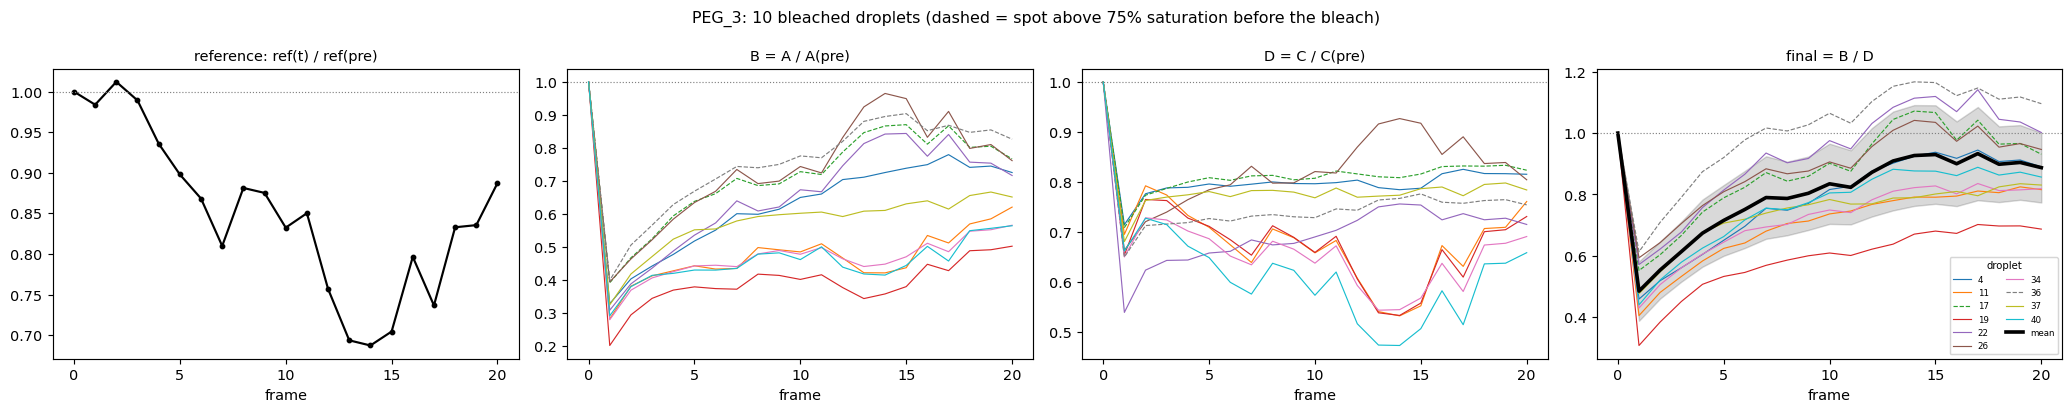

In [5]:
# Panel 1: reference, ref(t) / ref(pre): fading and imaging fluctuations of the whole field.
# Panel 2: B, the spot corrected by the reference.
# Panel 3: D, the whole droplet corrected by the reference.
# Panel 4: final = B / D, one line per droplet and the mean ± SD.
# Dashed lines: droplets whose spot is above 75% saturation before the bleach (saturation report).

for name, df in curves.groupby("file"):
    frames = df.groupby("frame")
    ref = frames["ref"].first()                       # one value per frame, index = frame number

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    figures[f"{name}_normalization_steps"] = fig

    axes[0].plot(ref.index, ref / ref.iloc[FRAME_PRE], "k-o", markersize=3)
    axes[0].xaxis.set_major_locator(MultipleLocator(5))

    for d, dd in df.groupby("droplet"):
        ls = "--" if dd["spot_pre_above_sat_th"].iloc[0] else "-"
        axes[1].plot(dd["frame"], dd["B"], ls, lw=0.8)
        axes[2].plot(dd["frame"], dd["D"], ls, lw=0.8)
        axes[3].plot(dd["frame"], dd["final"], ls, lw=0.8, label=str(d))
    mean, sd = frames["final"].mean(), frames["final"].std()
    axes[3].plot(mean.index, mean, "k-", lw=2.5, label="mean")
    axes[3].fill_between(mean.index, mean - sd, mean + sd, color="k", alpha=0.15)

    titles = ["reference: ref(t) / ref(pre)", "B = A / A(pre)", "D = C / C(pre)", "final = B / D"]
    for ax, title in zip(axes, titles):
        ax.axhline(1, color="gray", ls=":", lw=0.8)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("frame")
    axes[3].legend(fontsize=6, ncol=2, title="droplet", title_fontsize=7)

    axes[1].xaxis.set_major_locator(MultipleLocator(5))
    axes[2].xaxis.set_major_locator(MultipleLocator(5))
    axes[3].xaxis.set_major_locator(MultipleLocator(5))

    fig.suptitle(f"{name}: {df['droplet'].nunique()} bleached droplets "
                 f"(dashed = spot above 75% saturation before the bleach)", fontsize=11)

    plt.tight_layout()
    plt.show()

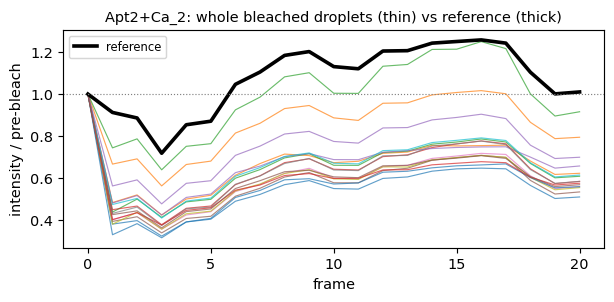

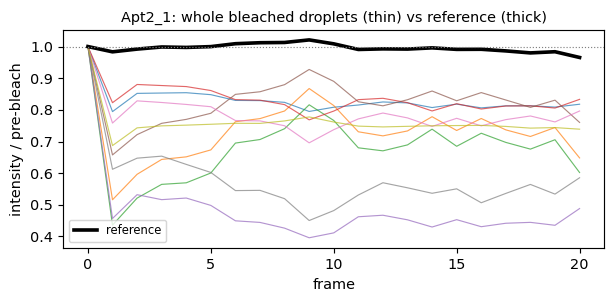

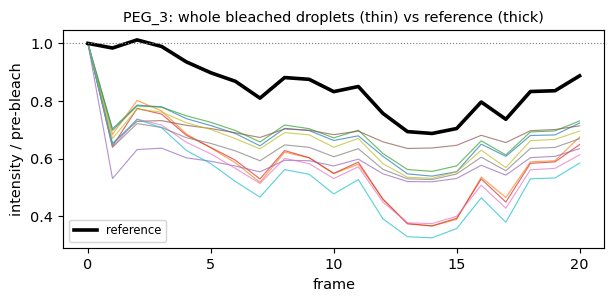

In [6]:
# Does the whole bleached droplet experiences the same global fluctuations as the reference ?

# tot(t)/tot(pre) of each bleached droplet (thin) and ref(t)/ref(pre) (thick).
# After the drop at the bleach their shapes should match

for name, df in curves.groupby("file"):
    ref = df.groupby("frame")["ref"].first()
    fig, ax = plt.subplots(figsize=(6, 3))
    for d, dd in df.groupby("droplet"):
        ax.plot(dd["frame"], dd["tot"] / dd["tot"].iloc[FRAME_PRE], lw=0.8, alpha=0.7)
    ax.plot(ref.index, ref / ref.iloc[FRAME_PRE], "k-", lw=2.5, label="reference")
    ax.axhline(1, color="gray", ls=":", lw=0.8)
    ax.set_xlabel("frame"); ax.set_ylabel("intensity / pre-bleach")
    ax.set_title(f"{name}: whole bleached droplets (thin) vs reference (thick)", fontsize=10)
    ax.legend(fontsize=8)
    ax.xaxis.set_major_locator(MultipleLocator(5))
    plt.tight_layout()
    plt.show()

# 38 of 39 references are saturated in Apt2_1 !
# TOT doesn’t behave consistently

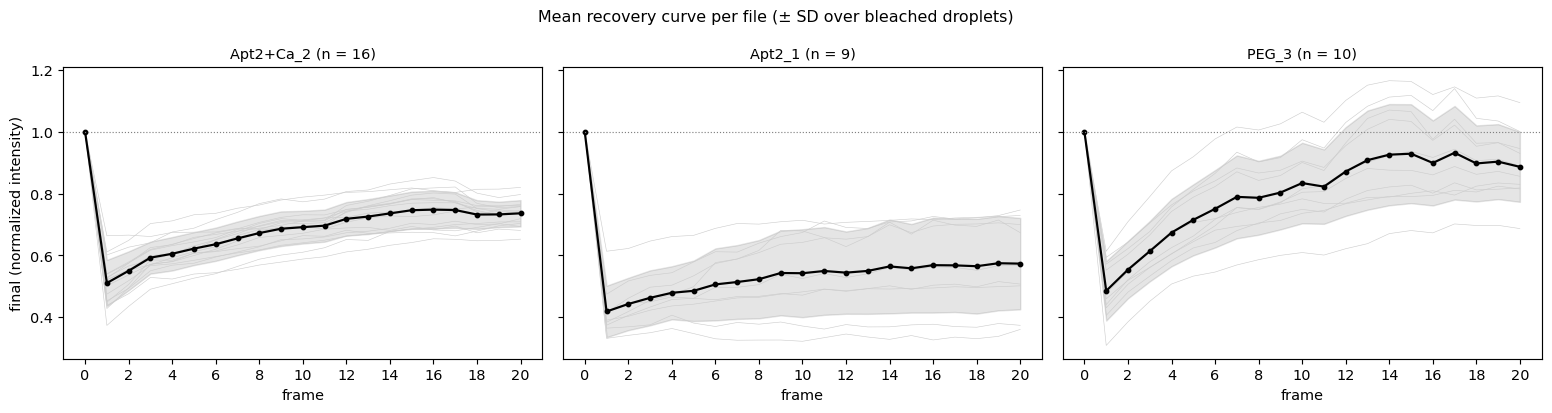

In [7]:
# Mean final curve of each file (± SD)

file_names = list(curves["file"].unique())
fig, axes = plt.subplots(1, len(file_names), squeeze=False, sharey=True, figsize=(5 * len(file_names), 4))
figures["mean_final_curves"] = fig

for ax, name in zip(axes[0], file_names):
    df = curves[curves["file"] == name]
    frames = df.groupby("frame")
    for _, dd in df.groupby("droplet"):
        ax.plot(dd["frame"], dd["final"], color="0.8", lw=0.4)
    mean, sd = frames["final"].mean(), frames["final"].std()

    ax.plot(mean.index, mean, "k-o", markersize=3)
    ax.fill_between(mean.index, mean - sd, mean + sd, color="k", alpha=0.1)
    ax.axhline(1, color="gray", ls=":", lw=0.8)
    ax.set_title(f"{name} (n = {df['droplet'].nunique()})", fontsize=10)
    ax.set_xlabel("frame")
    ax.xaxis.set_major_locator(MultipleLocator(2))

axes[0, 0].set_ylabel("final (normalized intensity)")
fig.suptitle("Mean recovery curve per file (± SD over bleached droplets)", fontsize=11)
plt.tight_layout()
plt.show()

# 3. Save results

In [8]:
# Save the curves (one file per image file) and the settings

OUT_DIR.mkdir(parents=True, exist_ok=True)

curves.to_csv(OUT_DIR / "recovery_curves.csv", index=False)

for name, df in curves.groupby("file"):
    df.to_csv(OUT_DIR / f"{name}_recovery_curves.csv", index=False)

with open(OUT_DIR / "recovery_parameters.json", "w") as fh:
    json.dump({"frame_pre": FRAME_PRE,
               "background_subtraction": False,
               "reference": "mean of all pixels of the reference droplets, pooled",
               "normalization": "A=spot/ref, B=A/A(pre), C=tot/ref, D=C/C(pre), final=B/D"},
              fh, indent=2)

FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
for fig_name, fig in figures.items():
    fig.savefig(FIG_DIR / f"{fig_name}.png", dpi=150, bbox_inches="tight")
print(f"{len(figures)} figures saved to {FIG_DIR}")

print("saved to", OUT_DIR)

4 figures saved to results/recovery_curves/figures
saved to results/recovery_curves
